# Power analysis GWAS synthetic data

In [323]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats

In [324]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans

In [326]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '38_9_120_38_maf_0.048_0.05.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [327]:
#wanted_maf = '0.01_0.01'
#wanted_maf = '0.024_0.025'
#wanted_maf = '0.048_0.05'
#wanted_maf = '0.49_0.49'
wanted_maf = '0.1_0.1'
#wanted_maf = '0.25_0.25'

In [329]:
snps = [f for f in os.listdir('./data/genotype') if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)

./data/genotype/60_2_120_60_maf_0.1_0.1.pkl


In [330]:
geno = pd.read_pickle(path_snp)
i = 0

In [332]:
i = 0

In [334]:
geno[geno.columns[i]].value_counts()
num_maj = geno[geno.columns[i]].value_counts()[1]
num_het = geno[geno.columns[i]].value_counts()[0]
try:
    num_min = geno[geno.columns[i]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min

In [336]:
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.10263578274760383

In [340]:
mean_min_H0 = 0
mean_het_H0 = 0
mean_maj_H0 = 0

In [343]:
mean_min = 152
mean_het = 159
mean_maj = 160
sigma_min = 8
sigma_het = 8
sigma_maj = 8
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[i]]), "pheno": pheno})

In [344]:
df_pheno

,geno,pheno
0,1,163.957058
1,1,160.936191
2,1,169.858106
3,1,151.773387
4,1,159.852009
...,...,...
2499,0,164.602729
2500,1,157.380716
2501,0,163.978458
2502,1,163.167867


<AxesSubplot:xlabel='geno', ylabel='pheno'>

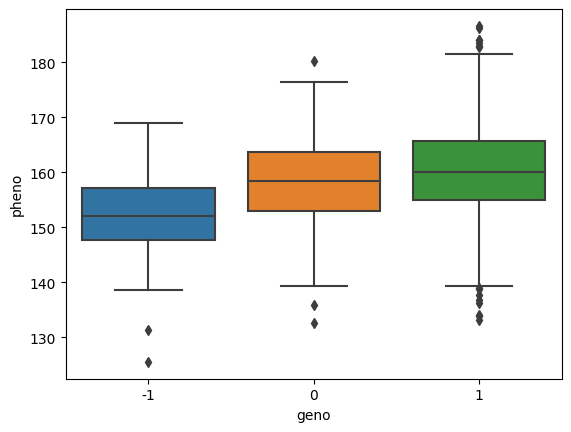

In [345]:
sns.boxplot(data=df_pheno, x="geno", y="pheno")

In [346]:
X = df_pheno[['geno']]
y = df_pheno[['pheno']]

In [347]:
reg = LinearRegression().fit(X, y)

In [348]:
reg.score(X, y)

0.031004460083088436

In [349]:
reg.coef_[0][0]

2.9870467482189045

In [350]:
reg.intercept_[0]

157.32678329353217

In [351]:
def find_lin_reg(X):
    y = reg.coef_[0][0]*X + reg.intercept_[0]
    return y

In [352]:
find_lin_reg(1)

160.3138300417511

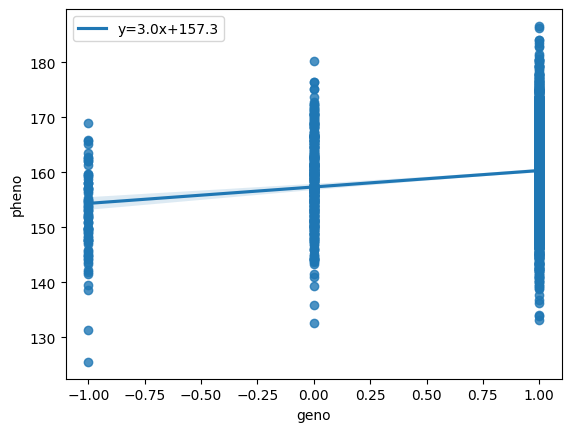

In [353]:
# use line_kws to set line label for legend
ax = sns.regplot(x="geno", y="pheno", data=df_pheno, 
 line_kws={'label':"y={0:.1f}x+{1:.1f}".format(reg.coef_[0][0],reg.intercept_[0])})

# plot legend
ax.legend()

plt.show()

In [354]:
reg.get_params()

{'copy_X': True,
 'fit_intercept': True,
 'n_jobs': None,
 'normalize': 'deprecated',
 'positive': False}

In [360]:
params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b

p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

In [361]:
p_values

[0.0, 0.0]

# Power

In [362]:
X

,geno
0,1
1,1
2,1
3,1
4,1
...,...
2499,0
2500,1
2501,0
2502,1


In [368]:
effect = 0
mean = 150

In [369]:
mean_min = mean - effect
mean_het = mean
mean_maj = mean + effect
sigma_min = 8
sigma_het = 8
sigma_maj = 8

In [372]:
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[i]]), "pheno": pheno})

In [391]:
def standy(pandasdf):
    return (pandasdf - pandasdf.mean())/stats.tstd(pandasdf)

In [392]:
standy(df_pheno[['pheno']])

,pheno
0,0.332463
1,-0.994205
2,-0.627463
3,-0.185150
4,1.304453
...,...
2499,0.834690
2500,-0.235195
2501,0.752595
2502,-1.322272


In [393]:
# SE under nul hypothesis
X = df_pheno[['geno']]
y = df_pheno[['pheno']]
reg = LinearRegression().fit(X, y)

In [394]:
params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b

p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

In [404]:
import pandas as pd
import numpy as np
from sklearn import linear_model
randn = np.random.randn

model = linear_model.LinearRegression()
model.fit(X=X, y=y)
y_pred = model.predict(X)

residuals = y - y_pred
residuals['c'] = residuals.iloc[:, 0]**2
sq = residuals['c']
print(sq)
standard_error = (sum(sq)/(total_humans))**0.5
print(standard_error)

           pheno
0     152.694888
1     141.986543
2     144.946740
3     148.516916
4     160.540407
...          ...
2499  156.748667
2500  148.112976
2501  156.086027
2502  139.338517
2503  132.692723

[2504 rows x 1 columns]
[[150.00510938]
 [150.00510938]
 [150.00510938]
 ...
 [150.03563116]
 [150.00510938]
 [150.00510938]]
0         7.234909
1        64.297408
2        25.587105
3         2.214719
4       110.992492
           ...    
2499     45.064852
2500      3.580170
2501     36.607295
2502    113.776201
2503    299.718716
Name: c, Length: 2504, dtype: float64
8.06998293686974


In [402]:
stats.tstd(df_pheno[['pheno']])

array([8.07160799])